In [1]:
### Analyzing Taylor Slough Bridge (TSB) water gauge data #######
import pandas as pd
import matplotlib.pyplot as plt

import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import rasterio

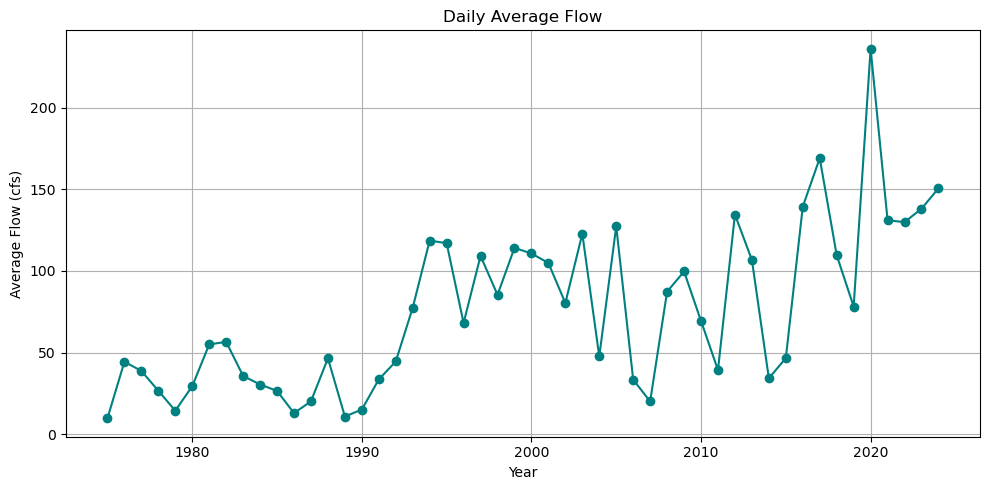

In [2]:
# Load data
file_path = '/Users/bz294/Documents/WhiteZone/Paper/CERP/sfwmd-data-202508061604_FLOW.csv'
df = pd.read_csv(file_path)



# Ensure VALUE is numeric
df['VALUE'] = pd.to_numeric(df['VALUE'], errors='coerce')

# Function to parse dates with 2-digit years assumed to be 1900s
def parse_timestamp(ts):
    try:
        # Try MM/DD/YY and assume 1900s
        dt = datetime.strptime(ts, '%m/%d/%y')
        if dt.year > 2025:  # Adjust if parsed as 2060 etc.
            dt = dt.replace(year=dt.year - 100)
        return dt
    except:
        try:
            return pd.to_datetime(ts, errors='coerce')
        except:
            return pd.NaT

# Apply custom parser to correct 2-digit years
df['TIMESTAMP'] = df['TIMESTAMP'].apply(parse_timestamp)

# Drop invalid dates and values
df = df.dropna(subset=['TIMESTAMP', 'VALUE'])

# Drop future years (e.g., beyond 2025)
df = df[df['TIMESTAMP'].dt.year < 2025]

# Extract year
df['YEAR'] = df['TIMESTAMP'].dt.year

# Group by year and compute annual average
annual_avg = df.groupby('YEAR')['VALUE'].mean().reset_index()

# Plotting
plt.figure(figsize=(10, 5))
plt.plot(annual_avg['YEAR'], annual_avg['VALUE'], marker='o', linestyle='-', color='teal')
plt.title('Daily Average Flow')
plt.xlabel('Year')
plt.ylabel('Average Flow (cfs)')
plt.grid(True)
plt.tight_layout()
plt.show()


In [3]:
%matplotlib agg
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 16  # base font size
plt.rcParams['axes.titlesize'] = 16  # title font size
plt.rcParams['axes.labelsize'] = 16  # axis label size
plt.rcParams['xtick.labelsize'] = 16
plt.rcParams['ytick.labelsize'] = 16

annual_avg = annual_avg[annual_avg['YEAR'] >= 1984]
plt.figure(figsize=(10, 5))
plt.plot(annual_avg['YEAR'], annual_avg['VALUE'], marker='o', linestyle='-', color='teal')

# Set x-axis ticks at 5-year intervals
plt.xticks(range(1984, 2025, 5))  # From 1984 to 2024 in steps of 5

plt.title('Daily Average Flow')
plt.xlabel('Year')
plt.ylabel('Average Flow (cfs)')
plt.grid(True)
plt.tight_layout()
plt.show()

plt.savefig('annual_flow_2024.tif', format='tiff', dpi=300, bbox_inches='tight')
plt.show()

/var/folders/yw/3l8t5xh50v33m6zjql7k1rzsvhfd38/T/ipykernel_74337/2521191724.py:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
/var/folders/yw/3l8t5xh50v33m6zjql7k1rzsvhfd38/T/ipykernel_74337/2521191724.py:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [4]:
import os
import numpy as np
import rasterio

# Define the input directory
#input_dir = "/Volumes/MaloneLab-1/Research/Whitezone/Result/Emulation/Final/CDthreshold06/CD_closest_GE/Subregion_2_transect/Region_0/"
input_dir = "/Volumes/MaloneLab-1/Research/Whitezone/Result/Emulation/Final/CDthreshold06/CD_closest_GE/Subregion_new/Region_0"
# Initialize a counter
total_pixel_count = 0

# Loop through all .tif files in the directory
for filename in os.listdir(input_dir):
    if filename.endswith(".tif"):
        filepath = os.path.join(input_dir, filename)
        with rasterio.open(filepath) as src:
            data = src.read(1)  # read the first band
            count = np.sum(data == 1)
            total_pixel_count += count
            print(f"{filename}: {count} pixels == 1")




raster_1984_cd.tif: 35239 pixels == 1
raster_1985.tif: 28558 pixels == 1
raster_1986_cd.tif: 30621 pixels == 1
raster_1987_cd.tif: 36607 pixels == 1
raster_1988_cd.tif: 35546 pixels == 1
raster_1989_cd.tif: 31284 pixels == 1
raster_1990_cd.tif: 31723 pixels == 1
raster_1991_cd.tif: 34481 pixels == 1
raster_1992_cd.tif: 33379 pixels == 1
raster_1993_cd.tif: 35192 pixels == 1
raster_1994.tif: 33818 pixels == 1
raster_1995_cd.tif: 37025 pixels == 1
raster_1996_cd.tif: 38858 pixels == 1
raster_1997_cd.tif: 36888 pixels == 1
raster_1998_cd.tif: 38937 pixels == 1
raster_1999.tif: 36391 pixels == 1
raster_2000_cd.tif: 37595 pixels == 1
raster_2001_cd.tif: 35264 pixels == 1
raster_2002_cd.tif: 35931 pixels == 1
raster_2003.tif: 35433 pixels == 1
raster_2004_cd.tif: 38368 pixels == 1
raster_2005_cd.tif: 35527 pixels == 1
raster_2006_cd.tif: 39627 pixels == 1
raster_2007_cd.tif: 37638 pixels == 1
raster_2008_cd.tif: 38403 pixels == 1
raster_2009.tif: 38314 pixels == 1
raster_2010_cd.tif: 40536 p

In [5]:
%matplotlib agg

# Set input directory
input_dir = "/Volumes/MaloneLab-1/Research/Whitezone/Result/Emulation/Final/CDthreshold06/CD_closest_GE/Subregion_new/Region_0/"
output_figure = os.path.join(input_dir, "/Users/bz294/Documents/WhiteZone/Figure/Pixel_vs_AnnualAvg_Correlation.tif")
# Count pixels equal to 1 in each .tif file
pixel_counts = []
tif_files = sorted([f for f in os.listdir(input_dir) if f.endswith(".tif")])

for filename in tif_files:
    filepath = os.path.join(input_dir, filename)
    with rasterio.open(filepath) as src:
        data = src.read(1)
        count = np.sum(data == 1)
        pixel_counts.append(count)

# Check matching lengths
if len(pixel_counts) != len(annual_avg):
    raise ValueError(f"Mismatch: {len(pixel_counts)} tif files vs {len(annual_avg)} annual_avg rows")

# Extract values
x = np.array(pixel_counts)[-11:]          # last 11 elements
y = annual_avg['VALUE'].to_numpy()[-11:]  # last 11 elements

# Calculate Pearson correlation
r, p = pearsonr(x, y)

# Plot
plt.figure(figsize=(8, 6))
plt.scatter(x, y, color='dodgerblue', edgecolor='k')
plt.xlabel("Number of Pixels == 1", fontsize=14)
plt.ylabel("Annual Average VALUE", fontsize=14)
plt.title(f"Pearson r = {r:.2f}, p = {p:.3f}", fontsize=16)
plt.grid(True)
plt.tight_layout()
plt.show()

plt.savefig(output_figure, dpi=300, format='tiff')  # Save as .tif
plt.close()

/var/folders/yw/3l8t5xh50v33m6zjql7k1rzsvhfd38/T/ipykernel_74337/1961179109.py:36: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [21]:
r

0.5587869881518234

In [19]:
p

7.050061370542293e-05

In [6]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import rasterio

# Define input and output
input_dir = "/Volumes/MaloneLab/Research/Whitezone/Result/Emulation/Final/CDthreshold06/CD_closest_GE/Subregion_2_transect/Region_0/"
output_figure = os.path.join(input_dir, "/Users/bz294/Documents/WhiteZone/Figure/Pixel_vs_AnnualAvg_SelectedYears.tif")

# Define target years
target_years = [1985, 1994, 1999, 2003, 2009, 2013, 2018, 2023]

# Get pixel counts for target years
year_pixel_dict = {}

for filename in os.listdir(input_dir):
    if filename.endswith(".tif"):
        for year in target_years:
            if str(year) in filename:
                filepath = os.path.join(input_dir, filename)
                with rasterio.open(filepath) as src:
                    data = src.read(1)
                    count = np.sum(data == 1)
                    year_pixel_dict[year] = count
                break

# Sort years and extract values
sorted_years = sorted(year_pixel_dict.keys())
pixel_counts = [year_pixel_dict[year] for year in sorted_years]

# Match with annual_avg
annual_avg_subset = annual_avg[annual_avg['YEAR'].isin(sorted_years)].sort_values(by='YEAR')
value_series = annual_avg_subset['VALUE'].to_numpy()

# Ensure years match
assert list(annual_avg_subset['YEAR']) == sorted_years, "Year mismatch between tif and annual_avg"

# Compute correlation
r, p = pearsonr(pixel_counts, value_series)

# Plot
plt.figure(figsize=(8, 6))
plt.scatter(pixel_counts, value_series, color='slateblue', edgecolor='k')
plt.xlabel("Number of Pixels == 1", fontsize=14)
plt.ylabel("Annual Average VALUE", fontsize=14)
plt.title(f"Correlation (Selected Years): r = {r:.2f}, p = {p:.3f}", fontsize=16)
plt.grid(True)
plt.tight_layout()
plt.savefig(output_figure, dpi=300, format='tiff')
plt.close()


In [7]:
# Define input and output
input_dir = "/Volumes/MaloneLab/Research/Whitezone/Result/Emulation/Final/CDthreshold06/CD_closest_GE/Subregion_2_transect/Region_0/"
output_figure = "/Users/bz294/Documents/WhiteZone/Figure/Pixel_TimeSeries_SelectedYears.tif"

# Define target years
target_years = list(range(1984, 2025))  # includes 2024

# Get pixel counts for target years
year_pixel_dict = {}

for filename in os.listdir(input_dir):
    if filename.endswith(".tif"):
        for year in target_years:
            if str(year) in filename:
                filepath = os.path.join(input_dir, filename)
                with rasterio.open(filepath) as src:
                    data = src.read(1)
                    count = np.sum(data == 1)
                    year_pixel_dict[year] = count
                break

# Convert pixel counts to km²
sorted_years = target_years
km2_values = [(year_pixel_dict[year] * 900) / 1_000_000 for year in sorted_years]

# Plot
fs = 20
plt.figure(figsize=(12, 6))
plt.plot(sorted_years, km2_values, marker='o', color='darkgreen', linewidth=2)
plt.xlabel("Year", fontsize=fs)
plt.ylabel("Mangrove area (km\u00b2)", fontsize=fs)  # km² with superscript
plt.title("Time Series of Mangrove Area", fontsize=fs)
plt.grid(True)
plt.xlim(1982, 2026)
plt.xticks(np.arange(1984, 2025, 5), fontsize = fs)
plt.yticks(fontsize=fs)
plt.tight_layout()
plt.savefig(output_figure, dpi=300, format='tiff')
plt.close()